In [3]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.tensorboard import SummaryWriter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps") # Für Macs
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"PyTorch {torch.__version__} | GPU-Gerät: {DEVICE}")

PyTorch 2.14.1+cu130 | GPU-Gerät: cuda


In [26]:
IMG_SIZE = 64
batch_size = 32

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

trainset = torchvision.datasets.FGVCAircraft(root="./data", split="train", download=True, transform=transform)
valset = torchvision.datasets.FGVCAircraft(root="./data", split="val", download=True, transform=transform)
testset = torchvision.datasets.FGVCAircraft(root="./data", split="test", download=True, transform=transform)

classes = trainset.classes

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=4)
valloader = torch.utils.data.DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=4)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=4)


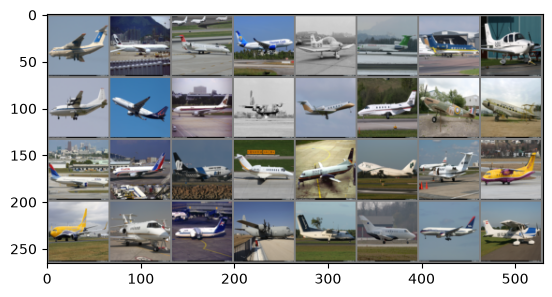

Il-76 777-300 CRJ-900 A330-200 DR-400 Tu-154 Gulfstream IV SR-20 An-12 A330-200 A330-300 C-130 Gulfstream IV Cessna 560 Spitfire DC-3  767-400 767-200 737-200 Cessna 525 Saab 2000 747-300 Cessna 525 Dornier 328 737-700 BAE-125 BAE 146-300 C-130 DHC-8-100 BAE-125 777-200 Cessna 172


In [27]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [28]:
from collections import Counter
from PIL import Image

raw_train = torchvision.datasets.FGVCAircraft(root="./data", split="train", download=True)

# Anzahl Klassen
num_classes = len(raw_train.classes)

# Input-Kanäle
img, label = raw_train[0]
modes = Counter(Image.open(f).mode for f in raw_train._image_files)
in_channels = len(img.getbands())          # RGB -> 3

# Bildgrößen (variieren!)
sizes = [Image.open(f).size for f in raw_train._image_files]   # liest nur den Header, schnell
widths, heights = zip(*sizes)

# Klassenverteilung (wichtig für die Wahl der Metrik)
counts = Counter(raw_train._labels)

print(f"Klassen: {num_classes}  (z.B. {raw_train.classes[:3]})")
print(f"Kanäle: {in_channels}  Modi: {dict(modes)}")
print(f"Breite: {min(widths)}–{max(widths)} px, Höhe: {min(heights)}–{max(heights)} px, "
      f"{len(set(sizes))} verschiedene Größen")
print(f"Bilder pro Klasse: {min(counts.values())}–{max(counts.values())}")

# Form nach dem Transform, also das, was das Netz tatsächlich bekommt
x, _ = trainset[0]
print(f"Tensor-Shape fürs Netz: {tuple(x.shape)}")   # (3, 32, 32)


Klassen: 100  (z.B. ['707-320', '727-200', '737-200'])
Kanäle: 3  Modi: {'RGB': 3334}
Breite: 775–1600 px, Höhe: 430–1188 px, 649 verschiedene Größen
Bilder pro Klasse: 33–34
Tensor-Shape fürs Netz: (3, 64, 64)


In [29]:
class BNNet(nn.Module):
    def __init__(self, in_channels, num_classes, img_size):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 32, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, 3, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128 * (img_size // 4) ** 2, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = torch.flatten(x, 1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)


In [30]:
def evaluate(net, loader, criterion):
    net.eval()   # wichtig: BatchNorm nutzt dann die gelernten Statistiken
    loss_sum = correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = net(images)
            loss_sum += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total


def train(net, writer, epochs=20, lr=0.01):
    net.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.perf_counter()
    for epoch in range(epochs):
        net.train()
        loss_sum = correct = total = 0
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        val_loss, val_acc = evaluate(net, valloader, criterion)
        for key, value in zip(history, (loss_sum / total, correct / total, val_loss, val_acc)):
            history[key].append(value)
            writer.add_scalar(key, value, epoch)
        print(f"[{epoch + 1:2d}] train loss {loss_sum / total:.3f} acc {100 * correct / total:5.1f} % | "
              f"val loss {val_loss:.3f} acc {100 * val_acc:5.1f} %")
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    duration = time.perf_counter() - start
    writer.flush()
    print(f"Finished Training on {DEVICE} in {duration:.1f} s")
    return history, duration


[ 1] train loss 4.676 acc   1.1 % | val loss 4.592 acc   1.5 %
[ 2] train loss 4.591 acc   1.2 % | val loss 4.587 acc   1.5 %
[ 3] train loss 4.579 acc   1.3 % | val loss 4.579 acc   1.4 %
[ 4] train loss 4.566 acc   1.5 % | val loss 4.536 acc   1.9 %
[ 5] train loss 4.552 acc   1.7 % | val loss 4.560 acc   1.9 %
[ 6] train loss 4.542 acc   1.5 % | val loss 4.543 acc   1.9 %
[ 7] train loss 4.544 acc   1.8 % | val loss 4.506 acc   2.9 %
[ 8] train loss 4.524 acc   2.2 % | val loss 4.489 acc   2.6 %
[ 9] train loss 4.513 acc   2.1 % | val loss 4.499 acc   3.0 %
[10] train loss 4.475 acc   3.0 % | val loss 4.448 acc   3.5 %
[11] train loss 4.448 acc   2.8 % | val loss 4.436 acc   3.6 %
[12] train loss 4.434 acc   3.6 % | val loss 4.433 acc   3.8 %
[13] train loss 4.392 acc   3.6 % | val loss 4.383 acc   4.6 %
[14] train loss 4.337 acc   4.5 % | val loss 4.363 acc   5.0 %
[15] train loss 4.322 acc   5.3 % | val loss 4.334 acc   5.1 %
[16] train loss 4.288 acc   5.3 % | val loss 4.339 acc 

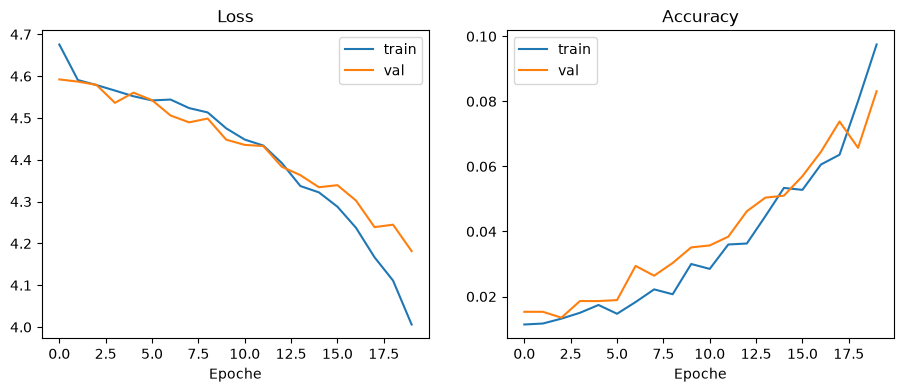

In [31]:
torch.manual_seed(SEED)
net = BNNet(in_channels, num_classes, IMG_SIZE)

writer = SummaryWriter("runs/fgvc/bnnet")
history, train_time = train(net, writer)
writer.close()

test_loss, test_acc = evaluate(net, testloader, nn.CrossEntropyLoss())
print(f"Test-Accuracy: {100 * test_acc:.2f} %  |  Trainingszeit: {train_time:.1f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history["train_loss"], label="train"); ax1.plot(history["val_loss"], label="val")
ax1.set(title="Loss", xlabel="Epoche"); ax1.legend()
ax2.plot(history["train_acc"], label="train"); ax2.plot(history["val_acc"], label="val")
ax2.set(title="Accuracy", xlabel="Epoche"); ax2.legend()
plt.show()
